# Why don't Olist customers come back, and what should Olist fix first?
### Retention, delivery experience and reviews in 96k Brazilian e-commerce orders · SQL (DuckDB) + Python

**Author:** Chi Nguyen · **Data:** [Olist Brazilian E-Commerce dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (Kaggle, CC BY-NC-SA 4.0) · **Period:** Jan 2017 – Aug 2018

---

### Executive summary

**Answer: retention is low for structural reasons, and delivery experience barely moves it. Lateness, however, is the
main driver of negative reviews. Olist should treat on-time delivery as review protection, and start with the Rio de
Janeiro route.**

| Finding | Evidence |
|---|---|
| **True retention is ~2 %, not 3 %** | Measured naively, 3 % of customers "repeat", but 30 % of second orders are split baskets placed the same day. Only **1.9 %** return within 180 days, and **3.0 %** within a year (Kaplan-Meier, censoring handled). |
| **Experience moves retention only at the margin** | A 1–2 star first order lowers the return rate by **0.4 points**. Lateness has no separate effect once the review is controlled for, and a model using every first-order signal reaches only **AUC 0.55**. |
| **Lateness drives bad reviews** | Negative reviews go from **~10 %** on time to **~80 %** at 8+ days late. With controls, a 1–3 day delay multiplies the odds of a 1–2 star review by **3.7**. Comparing orders from the *same seller* gives the same answer. |
| **Lateness is a carrier problem, concentrated by route** | Late orders spend **26 days with the carrier vs 7** for on-time orders. **Rio de Janeiro** generates **42 %** of all excess late orders (12 % late rate on 12k orders vs 4.5 % for São Paulo). |
| **Fixing it pays off in reviews, not retention** | Halving late deliveries avoids **~167 negative reviews per 10k orders** (13 % of all negative reviews), but adds only about **1 returning customer per 10k**, which is not statistically distinguishable from zero. |

**Techniques:** SQL data model with window functions (DuckDB) · cohort analysis · Kaplan-Meier survival and log-rank
tests · logistic regression with clustered errors · within-seller fixed effects · mediation check (direct vs total effect) ·
empirical-Bayes shrinkage · time-split gradient boosting with permutation importance · counterfactual simulation with
parameter uncertainty.

*Data model: [`sql/01_staging.sql`](../sql/01_staging.sql) · Figures: [`reports/figures`](../reports/figures)*

## 0. The question and how this notebook answers it

Olist is a Brazilian marketplace integrator. Small sellers list through Olist, and customers buy on large Brazilian
marketplaces. Almost no customer buys twice. Leadership wants to know:

> **Is low retention a property of the market, or a symptom of a bad experience we can fix, and where should we invest first?**

| § | Question | Main technique |
|---|---|---|
| 1 | Can the data be trusted, and what traps does it hide? | SQL integrity checks, identity resolution |
| 2 | How low is retention, really? | Cohort retention (SQL window functions), Kaplan-Meier survival |
| 3 | Does late delivery hurt reviews? | Logistic regression with controls, within-seller fixed effects |
| 4 | Do bad experiences reduce repurchase? | Logistic regression, marginal effects, survival curves by experience |
| 5 | Can we segment customers who buy once? | RFM stress test, first-order segmentation with Wilson intervals |
| 6 | Can we predict who will return? | Time-split ML: logistic vs gradient boosting, lift, calibration |
| 7 | Who causes late deliveries: sellers or routes? | Empirical-Bayes shrinkage, concentration curve, delay decomposition |
| 8 | What is fixing it worth? | Counterfactual simulation with parameter uncertainty |
| 9 | Recommendation and limitations | |

**How the work is split:** SQL does the data work (cleaning, joins, cohorts, aggregates) against a DuckDB model built
by `sql/01_staging.sql`. Python does what SQL cannot (statistics, models and charts).

In [1]:
import sys, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf
from scipy import stats
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from IPython.core.magic import register_cell_magic

import viz
from viz import titles, label_points, save, SERIES, CONTEXT, HIGHLIGHT, INK_2, MUTED

viz.apply_style()
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
RNG = np.random.default_rng(7)

con = duckdb.connect("../data/olist.duckdb", read_only=True)

@register_cell_magic
def sql(line, cell):
    # %%sql [name]: run the cell as DuckDB SQL, show the result, and keep it as a DataFrame called `name`.
    df = con.execute(cell).df()
    if line.strip():
        get_ipython().user_ns[line.strip()] = df
    return df

def wilson(k, n, z=1.96):
    # Wilson score interval: honest error bars for small proportions such as a 2% repeat rate.
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

## 1. Data audit: what can we trust?

The raw data has 9 tables. `sql/01_staging.sql` turns them into an order fact table (`fct_orders`) and a customer
table (`dim_customers`). Before analysing anything, check coverage, keys and time range.

In [2]:
%%sql audit
SELECT 'orders'                       AS check_name, count(*)::VARCHAR AS result FROM fct_orders
UNION ALL SELECT 'delivered orders',  count(*)::VARCHAR FROM fct_orders WHERE order_status = 'delivered'
UNION ALL SELECT 'orders with no items',   count(*)::VARCHAR FROM fct_orders WHERE n_items IS NULL
UNION ALL SELECT 'orders with no review',  count(*)::VARCHAR FROM fct_orders WHERE review_score IS NULL
UNION ALL SELECT 'delivered but no delivery date', count(*)::VARCHAR FROM fct_orders
          WHERE order_status = 'delivered' AND delivered_at IS NULL
UNION ALL SELECT 'reviews in raw table',  count(*)::VARCHAR FROM raw_reviews
UNION ALL SELECT 'orders with >1 raw review', count(*)::VARCHAR FROM
          (SELECT order_id FROM raw_reviews GROUP BY 1 HAVING count(*) > 1)
UNION ALL SELECT 'delivered orders missing distance', count(*)::VARCHAR FROM fct_orders
          WHERE order_status = 'delivered' AND distance_km IS NULL

,check_name,result
0,orders,99441
1,delivered orders,96478
2,orders with no items,775
3,orders with no review,768
4,delivered but no delivery date,8
5,reviews in raw table,99224
6,orders with >1 raw review,547
7,delivered orders missing distance,476


In [3]:
%%sql monthly
SELECT order_month, count(*) AS orders
FROM fct_orders
GROUP BY 1 ORDER BY 1

,order_month,orders
0,2016-09-01,4
1,2016-10-01,324
2,2016-12-01,1
3,2017-01-01,800
4,2017-02-01,1780
5,2017-03-01,2682
6,2017-04-01,2404
7,2017-05-01,3700
8,2017-06-01,3245
9,2017-07-01,4026


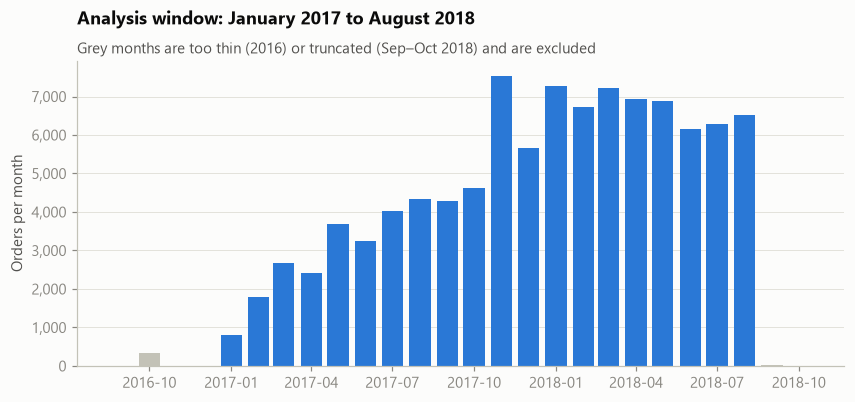

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
in_window = (monthly.order_month >= "2017-01-01") & (monthly.order_month <= "2018-08-01")
ax.bar(monthly.order_month, monthly.orders, width=24, color=np.where(in_window, HIGHLIGHT, CONTEXT))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(axis="x", visible=False)
ax.set_ylabel("Orders per month")
titles(ax, "Analysis window: January 2017 to August 2018",
       "Grey months are too thin (2016) or truncated (Sep–Oct 2018) and are excluded")
save(fig, "fig01_order_volume")
plt.show()

### 1.1 Trap #1: `customer_id` is not a customer

In [5]:
%%sql identity
SELECT count(DISTINCT customer_id)        AS customer_ids,
       count(DISTINCT customer_unique_id) AS real_customers,
       count(*)                           AS orders,
       count(*) FILTER (WHERE customer_id IN (
           SELECT customer_id FROM raw_orders GROUP BY 1 HAVING count(*) > 1)) AS orders_sharing_a_customer_id
FROM raw_orders JOIN raw_customers USING (customer_id)

,customer_ids,real_customers,orders,orders_sharing_a_customer_id
0,99441,96096,99441,0


Every order has its own `customer_id` (99,441 IDs for 99,441 orders, and none is ever reused). Measured on
`customer_id`, the repeat rate is **exactly 0 %**. Only `customer_unique_id` links a person's orders, and every
customer metric below uses it.

### 1.2 Trap #2: most "repeat purchases" are split baskets

In [6]:
%%sql gaps
SELECT CASE WHEN days_to_second = 0   THEN '0: same day'
            WHEN days_to_second <= 7  THEN '1–7 days'
            WHEN days_to_second <= 30 THEN '8–30 days'
            WHEN days_to_second <= 90 THEN '31–90 days'
            WHEN days_to_second <= 180 THEN '91–180 days'
            ELSE '181+ days' END             AS gap_to_second_order,
       count(*)                              AS customers,
       round(100.0 * count(*) / sum(count(*)) OVER (), 1) AS pct_of_repeaters
FROM dim_customers
WHERE n_orders > 1
GROUP BY 1
ORDER BY min(days_to_second)

,gap_to_second_order,customers,pct_of_repeaters
0,0: same day,867,30.2
1,1–7 days,207,7.2
2,8–30 days,390,13.6
3,31–90 days,503,17.5
4,91–180 days,423,14.7
5,181+ days,485,16.9


About **30 % of second orders are placed on the same day as the first**, usually minutes apart. These are
customers splitting one shopping trip into several checkouts, not loyalty. Counting them would inflate retention by
about 40 %. From here on, **a customer "returns" only if they buy again on a later day** (`days_to_return`
in `dim_customers`).

### 1.3 What the audit tells us
- 96,478 delivered orders; 775 orders without items and 768 without reviews are tiny and are dropped where needed.
- Reviews have duplicates in both directions. The staging layer keeps the latest review per order with a `ROW_NUMBER()` window.
- Distance is available for 99.5 % of delivered orders (zip-prefix centroids, median of ~50 geocoded points each).

## 2. How low is retention, really?

### 2.1 Monthly cohort retention (SQL)

For each monthly cohort of first-time buyers, what share bought again *k* months later?

In [7]:
%%sql cohorts
WITH purchases AS (                      -- every valid purchase in the window
    SELECT f.customer_unique_id, f.purchased_at
    FROM fct_orders f, params p
    WHERE f.purchase_seq IS NOT NULL
      AND f.purchased_at::DATE BETWEEN p.window_start AND p.window_end
),
activity AS (                            -- later-day purchases, by months since first purchase
    SELECT d.cohort_month,
           d.customer_unique_id,
           date_diff('month', d.cohort_month, date_trunc('month', p.purchased_at)) AS month_offset
    FROM dim_customers d
    JOIN purchases p USING (customer_unique_id)
    WHERE p.purchased_at::DATE > d.first_purchased_at::DATE
),
sizes AS (
    SELECT cohort_month, count(*) AS cohort_size FROM dim_customers GROUP BY 1
)
SELECT s.cohort_month,
       s.cohort_size,
       a.month_offset,
       count(DISTINCT a.customer_unique_id)                         AS returning,
       count(DISTINCT a.customer_unique_id) * 1.0 / s.cohort_size  AS retention
FROM sizes s
JOIN activity a USING (cohort_month)
WHERE a.month_offset BETWEEN 0 AND 12
GROUP BY s.cohort_month, s.cohort_size, a.month_offset
ORDER BY 1, 3

,cohort_month,cohort_size,month_offset,returning,retention
0,2017-01-01,753,0,2,0.003
1,2017-01-01,753,1,3,0.004
2,2017-01-01,753,2,2,0.003
3,2017-01-01,753,3,1,0.001
4,2017-01-01,753,4,3,0.004
...,...,...,...,...,...
176,2018-06-01,5921,1,25,0.004
177,2018-06-01,5921,2,16,0.003
178,2018-07-01,6016,0,21,0.003
179,2018-07-01,6016,1,31,0.005


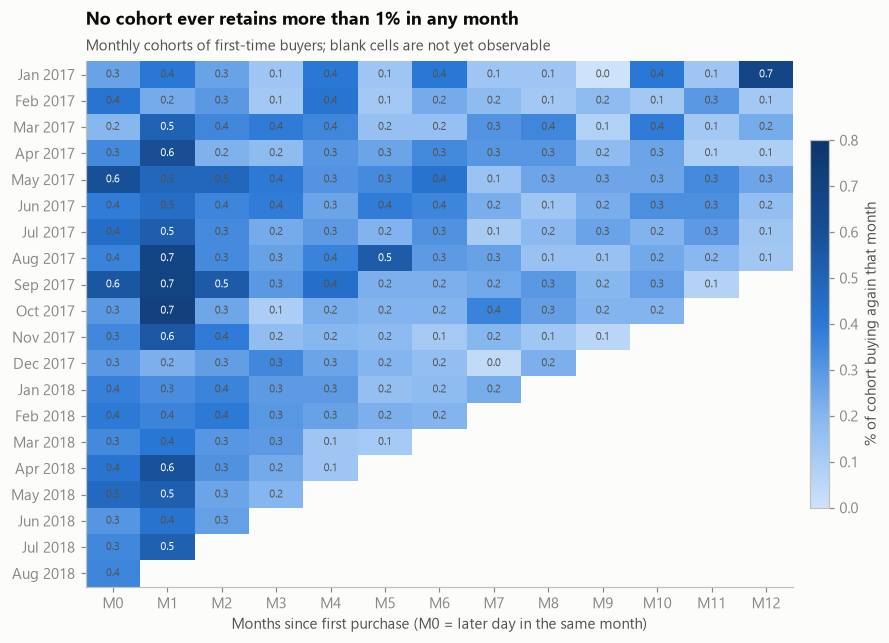

In [8]:
grid = cohorts.pivot(index="cohort_month", columns="month_offset", values="retention").reindex(columns=range(0, 13))
last = pd.Timestamp("2018-08-01")
# Blank out cells the data cannot observe yet (cohort month + offset beyond Aug 2018).
for cm in grid.index:
    for k in grid.columns:
        if cm + pd.DateOffset(months=int(k)) > last:
            grid.loc[cm, k] = np.nan
        elif np.isnan(grid.loc[cm, k]):
            grid.loc[cm, k] = 0.0

fig, ax = plt.subplots(figsize=(10, 6.2))
im = ax.imshow(grid.values * 100, cmap=viz.SEQ, aspect="auto", vmin=0, vmax=0.8)
ax.set_xticks(range(13), [f"M{k}" for k in range(13)])
ax.set_yticks(range(len(grid)), [d.strftime("%b %Y") for d in grid.index])
ax.grid(False)
for (i, j), v in np.ndenumerate(grid.values * 100):
    if not np.isnan(v):
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7,
                color="white" if v > 0.5 else INK_2)
cb = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.02)
cb.set_label("% of cohort buying again that month", color=INK_2)
ax.set_xlabel("Months since first purchase (M0 = later day in the same month)")
titles(ax, "No cohort ever retains more than 1% in any month",
       "Monthly cohorts of first-time buyers; blank cells are not yet observable")
save(fig, "fig02_cohort_retention")
plt.show()

### 2.2 Survival analysis: probability of ever returning

Cohort tables waste information: a customer who bought in July 2018 has only weeks of history, so the late
cohorts look worse simply because they're young. **Kaplan-Meier** treats those customers as *censored* (still
"at risk" of returning), which gives an unbiased curve of the cumulative probability of a return.

In [9]:
%%sql surv
SELECT d.customer_unique_id,
       coalesce(d.days_to_return, d.follow_up_days) AS duration,
       d.days_to_return IS NOT NULL                 AS returned,
       f.is_late,
       f.review_score
FROM dim_customers d
JOIN fct_orders f ON f.order_id = d.first_order_id
WHERE coalesce(d.days_to_return, d.follow_up_days) > 0

,customer_unique_id,duration,returned,is_late,review_score
0,0000f6ccb0745a6a4b88665a16c9f078,323,False,False,4
1,00115fc7123b5310cf6d3a3aa932699e,587,False,False,4
2,00522457bba00bba576a34fd9b4808fd,517,False,False,5
3,014e4042a6b3ed0b1a6cd14c7639bb84,149,False,False,5
4,0165dc4e0c64d7c1e17757ab8676f213,92,False,False,5
...,...,...,...,...,...
94702,ff64dc057067aecad9bf2c94b272e90a,527,False,False,5
94703,ff96fbbcff0db5c4442796b8ab8b474d,76,False,False,5
94704,ffaa5b5559566bb4dbf71d554310e760,483,False,False,5
94705,ffbcd1715dfbead64e1b896044d73c76,115,False,False,5


P(return within  90 days) = 1.28%
P(return within 180 days) = 1.92%
P(return within 365 days) = 2.99%
Naive share of customers with a later-day purchase: 2.17% (biased low by censoring)


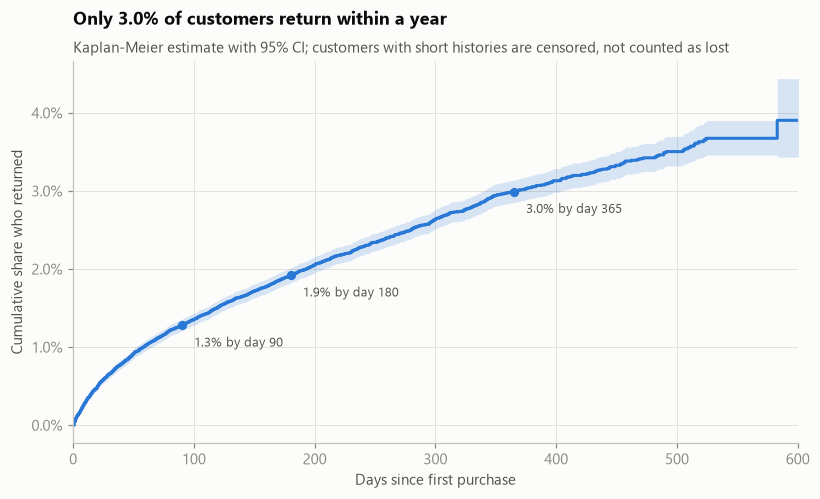

In [10]:
kmf = KaplanMeierFitter().fit(surv.duration, surv.returned)
ret = lambda t: 1 - kmf.survival_function_at_times(t).iloc[0]
lo, hi = kmf.confidence_interval_survival_function_.iloc[:, 1], kmf.confidence_interval_survival_function_.iloc[:, 0]
print(f"P(return within  90 days) = {ret(90):.2%}")
print(f"P(return within 180 days) = {ret(180):.2%}")
print(f"P(return within 365 days) = {ret(365):.2%}")
print(f"Naive share of customers with a later-day purchase: {surv.returned.mean():.2%} (biased low by censoring)")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
t = kmf.survival_function_.index
ax.fill_between(t, (1 - hi) * 100, (1 - lo) * 100, color=HIGHLIGHT, alpha=0.18, linewidth=0, step="post")
ax.step(t, (1 - kmf.survival_function_.iloc[:, 0]) * 100, where="post", color=HIGHLIGHT)
for d in (90, 180, 365):
    ax.annotate(f"{ret(d):.1%} by day {d}", (d, ret(d) * 100), xytext=(8, -14), textcoords="offset points",
                fontsize=8.5, color=INK_2)
    ax.plot(d, ret(d) * 100, "o", color=HIGHLIGHT, markersize=5)
ax.set_xlim(0, 600)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.set(xlabel="Days since first purchase", ylabel="Cumulative share who returned")
titles(ax, f"Only {ret(365):.1%} of customers return within a year",
       "Kaplan-Meier estimate with 95% CI; customers with short histories are censored, not counted as lost")
save(fig, "fig03_survival")
plt.show()

**Retention is structurally tiny.** Even with censoring handled properly, only about 2–3 % of customers return within a
year. For context, the dataset's own description notes that Olist sells *through* large marketplaces, so the customer's
relationship is with the marketplace, not with Olist or the seller. That is the first hypothesis to test:

> *H1: low retention is mainly structural. Experience (delivery, reviews) moves it, but only at the margin.*

## 3. Does late delivery hurt reviews?

In [11]:
%%sql delay_buckets
SELECT CASE WHEN delay_days <= -15 THEN '1. 15+ days early'
            WHEN delay_days <= -7  THEN '2. 7–14 days early'
            WHEN delay_days <= 0   THEN '3. 0–6 days early'
            WHEN delay_days <= 3   THEN '4. 1–3 days late'
            WHEN delay_days <= 7   THEN '5. 4–7 days late'
            ELSE                        '6. 8+ days late' END    AS delivery_vs_promise,
       count(*)                                                AS orders,
       round(avg(review_score), 2)                             AS avg_score,
       round(avg((review_score <= 2)::INT), 3)                 AS share_1_2_star,
       round(avg((review_score = 5)::INT), 3)                  AS share_5_star
FROM fct_orders, params
WHERE order_status = 'delivered' AND delay_days IS NOT NULL AND review_score IS NOT NULL
  AND purchased_at::DATE BETWEEN window_start AND window_end
GROUP BY 1 ORDER BY 1

,delivery_vs_promise,orders,avg_score,share_1_2_star,share_5_star
0,1. 15+ days early,34526,4.32,0.090,0.643
1,2. 7–14 days early,40961,4.30,0.089,0.626
2,3. 0–6 days early,13695,4.17,0.107,0.562
3,4. 1–3 days late,1851,3.29,0.321,0.332
4,5. 4–7 days late,1748,2.10,0.677,0.141
5,6. 8+ days late,2779,1.70,0.793,0.070


In [12]:
%%sql by_day
SELECT greatest(least(delay_days, 20), -30) AS delay_days,
       count(*)                             AS n,
       sum((review_score <= 2)::INT)        AS negative
FROM fct_orders, params
WHERE order_status = 'delivered' AND delay_days IS NOT NULL AND review_score IS NOT NULL
  AND purchased_at::DATE BETWEEN window_start AND window_end
GROUP BY 1 ORDER BY 1

,delay_days,n,negative
0,-30,2506,269.0
1,-29,483,49.0
2,-28,742,76.0
3,-27,807,96.0
4,-26,789,72.0
5,-25,905,93.0
6,-24,1058,110.0
7,-23,1246,137.0
8,-22,1833,172.0
9,-21,2801,258.0


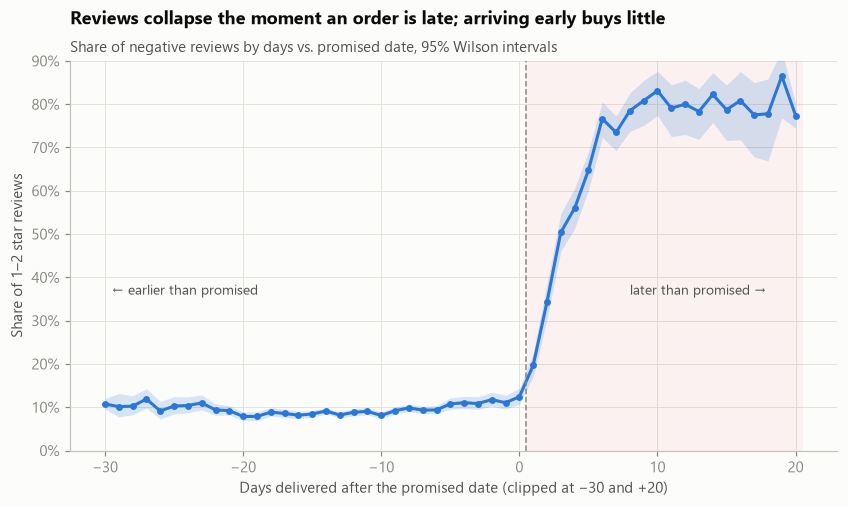

In [13]:
lo_, hi_ = wilson(by_day.negative, by_day.n)
p = by_day.negative / by_day.n
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.axvspan(0.5, 20.5, color=SERIES[7], alpha=0.06, linewidth=0)
ax.fill_between(by_day.delay_days, lo_, hi_, color=HIGHLIGHT, alpha=0.18, linewidth=0)
ax.plot(by_day.delay_days, p, color=HIGHLIGHT, marker="o", markersize=3.5)
ax.axvline(0.5, color=MUTED, linewidth=1, linestyle="--")
ax.text(8, 0.36, "later than promised →", color=INK_2, fontsize=9)
ax.text(-29.5, 0.36, "← earlier than promised", color=INK_2, fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylim(0, 0.9)
ax.set(xlabel="Days delivered after the promised date (clipped at −30 and +20)", ylabel="Share of 1–2 star reviews")
titles(ax, "Reviews collapse the moment an order is late; arriving early buys little",
       "Share of negative reviews by days vs. promised date, 95% Wilson intervals")
save(fig, "fig04_delay_vs_reviews")
plt.show()

The pattern is a **cliff, not a slope**. Negative reviews sit at about 9–11 % for anything on time, then jump to about
a third at 1–3 days late, two-thirds at 4–7 days, and about 80 % beyond a week. Arriving two weeks early is only slightly
better than arriving on the day (9 % vs 11 % negative).

But late orders differ in other ways too: they travel further, go to remote states, and carry heavier or bulkier
products. Is it lateness, or is it what tends to be late? A model with controls answers that.

### 3.1 Logistic regression with controls

$P(\text{1–2 star}) \sim$ delivery bucket + log distance + freight share of price + items + multi-seller order +
instalments + payment type + product category + customer state + purchase month.

In [14]:
%%sql orders_model
SELECT f.order_id, f.seller_id, f.review_score,
       (f.review_score <= 2)::INT                  AS negative,
       (f.review_score = 5)::INT                   AS five_star,
       f.delay_days, f.is_late::INT                AS late,
       f.delivery_days, f.distance_km,
       f.freight_value / nullif(f.items_value, 0)  AS freight_ratio,
       f.items_value, f.n_items, (f.n_sellers > 1)::INT AS multi_seller,
       f.installments, f.payment_type, f.category, f.customer_state,
       strftime(f.order_month, '%Y-%m')           AS month
FROM fct_orders f, params p
WHERE f.order_status = 'delivered' AND f.delay_days IS NOT NULL AND f.review_score IS NOT NULL
  AND f.distance_km IS NOT NULL AND f.items_value > 0
  AND f.purchased_at::DATE BETWEEN p.window_start AND p.window_end

,order_id,seller_id,review_score,negative,five_star,delay_days,late,delivery_days,distance_km,freight_ratio,items_value,n_items,multi_seller,installments,payment_type,category,customer_state,month
0,41272756ecddd9a9ed0180413cc22fb6,ef506c96320abeedfb894c34db06f478,4,0,0,-12,0,20,2481.690,0.678,25.99,1,0,4,credit_card,telephony,PA,2017-10
1,91d1bf2b7745903cb0d17162d1bbd750,54a1852d1b8f10312c55e906355666ee,4,0,0,-33,0,11,773.834,0.269,59.99,1,0,1,credit_card,sports_leisure,DF,2017-01
2,9da02db988be4c6560597e90391a4cdc,701938c450705b8ae65fc923b70f35c7,5,0,1,-14,0,9,410.114,0.231,103.97,1,0,2,credit_card,furniture_living_room,SP,2017-04
3,7c93ee5c562cc8509ceb10539d832659,3be634553519fb6536a03e1358e9fdc7,5,0,1,-7,0,9,9.377,0.098,219.90,1,0,1,boleto,housewares,SP,2018-04
4,cbbac32b13e7fbbcc8e815705213e1e0,e504a4e2efaa45cbff7e268a2c58c956,5,0,1,-7,0,19,161.095,0.176,99.90,1,0,2,credit_card,housewares,SP,2018-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95080,104bc860b4c9a9d28566dfd1093997e0,669ae81880e08f269a64487cfb287169,5,0,1,-22,0,10,1231.953,0.198,115.00,1,0,1,credit_card,books_general_interest,MG,2018-06
95081,272e6f76eb38eeae926978ca915c5758,c157bdeedcbc9a8e3c8bf0d87ff24428,5,0,1,-2,0,24,470.645,0.218,94.99,1,0,4,credit_card,unknown,SC,2017-05
95082,bc549579fe8b9728bac120abd8c20174,16090f2ca825584b5a147ab24aa30c86,5,0,1,-2,0,7,66.037,0.282,27.90,1,0,1,boleto,food,SP,2018-05
95083,39a0e2f723def2e12a51e963006c9242,dc4a0fc896dc34b0d5bfec8438291c80,1,1,0,-9,0,17,285.637,0.391,37.18,1,0,2,credit_card,bed_bath_table,MG,2017-04


In [15]:
m = orders_model.copy()
m["bucket"] = pd.cut(m.delay_days, [-999, -15, -7, 0, 3, 7, 999],
                     labels=["15+ early", "7–14 early", "0–6 early", "1–3 late", "4–7 late", "8+ late"])
top_cats = m.category.value_counts().index[:25]
m["cat"] = np.where(m.category.isin(top_cats), m.category, "other")
top_states = m.customer_state.value_counts().index[:12]
m["state"] = np.where(m.customer_state.isin(top_states), m.customer_state, "other")
m["log_km"] = np.log1p(m.distance_km)
m["freight_ratio"] = m.freight_ratio.clip(upper=3)
m["log_value"] = np.log(m.items_value)

controls = "log_km + freight_ratio + log_value + n_items + multi_seller + installments + C(payment_type) + C(cat) + C(state) + C(month)"
f_neg = f"negative ~ C(bucket, Treatment('0–6 early')) + {controls}"
logit_neg = smf.logit(f_neg, m).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(m.seller_id)[0]})

def odds_table(res, prefix):
    rows = [k for k in res.params.index if k.startswith(prefix)]
    ci = res.conf_int().loc[rows]
    out = pd.DataFrame({"odds ratio": np.exp(res.params[rows]), "95% CI low": np.exp(ci[0]), "95% CI high": np.exp(ci[1]),
                        "p": res.pvalues[rows]})
    out.index = [r.split("[T.")[1].rstrip("]") for r in rows]
    return out

print(f"n = {int(logit_neg.nobs):,} orders · pseudo R² = {logit_neg.prsquared:.3f} · SEs clustered by seller")
odds_neg = odds_table(logit_neg, "C(bucket")
odds_neg

n = 95,085 orders · pseudo R² = 0.185 · SEs clustered by seller


,odds ratio,95% CI low,95% CI high,p
15+ early,0.658,0.604,0.716,7.794e-22
7–14 early,0.748,0.688,0.815,2.128e-11
1–3 late,3.693,3.238,4.211,1.405e-84
4–7 late,16.572,14.758,18.609,0.000e+00
8+ late,28.573,25.482,32.039,0.000e+00


### 3.2 Robustness: compare orders *from the same seller*

A seller with poor packaging or service could produce both late deliveries and bad reviews. A **within-seller
(fixed-effects) linear probability model** compares only orders from the same seller, removing everything constant
about that seller.

In [16]:
fe = m[m.groupby("seller_id").order_id.transform("size") >= 20].copy()
cols = ["negative", "late", "log_km", "freight_ratio", "log_value", "n_items", "multi_seller", "installments"]
demeaned = fe[cols] - fe.groupby("seller_id")[cols].transform("mean")
pooled = smf.ols("negative ~ late + log_km + freight_ratio + log_value + n_items + multi_seller + installments", fe) \
            .fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(fe.seller_id)[0]})
within = smf.ols("negative ~ late + log_km + freight_ratio + log_value + n_items + multi_seller + installments - 1", demeaned) \
            .fit(cov_type="cluster", cov_kwds={"groups": pd.factorize(fe.seller_id)[0]})
pd.DataFrame({
    "effect of 'late' on P(1–2 star), pp": [pooled.params.late * 100, within.params.late * 100],
    "95% CI": [f"{pooled.conf_int().loc['late', 0]*100:.1f} – {pooled.conf_int().loc['late', 1]*100:.1f}",
               f"{within.conf_int().loc['late', 0]*100:.1f} – {within.conf_int().loc['late', 1]*100:.1f}"],
    "orders": [int(pooled.nobs), int(within.nobs)],
}, index=["Pooled (across sellers)", f"Within seller ({fe.seller_id.nunique():,} sellers with ≥20 orders)"])

,"effect of 'late' on P(1–2 star), pp",95% CI,orders
Pooled (across sellers),53.800,52.3 – 55.3,83296
Within seller (786 sellers with ≥20 orders),53.041,51.5 – 54.5,83296


**Reading the model**
- With every control in place, a 1–3 day delay nearly **quadruples** the odds of a 1–2 star review (OR ≈ 3.7), and
  8+ days multiplies them almost **thirtyfold** (OR ≈ 29) compared with "0–6 days early".
- The within-seller estimate (+53 pp) is almost identical to the pooled one (+54 pp), so the effect is **not** explained
  by bad sellers being both slow and disappointing. Lateness itself drives the reviews.
- Early delivery helps, but only a little. "15+ days early" lowers the odds of a negative review by about a third, which
  is roughly 2 percentage points, against a penalty of 20–70 points for being late. Promised dates average 24 days
  against a median actual of 10, so **most of the promise's slack is not rewarded by customers.** Tightening promises
  could help conversion, but that needs an A/B test, because a tighter promise also creates more "late" orders.

## 4. Do bad experiences reduce repurchase?

**Sample:** customers whose first order was delivered and who have **at least 180 days of follow-up** (first purchase
on or before 4 Mar 2018), so every customer had the same chance to return.
**Outcome:** a purchase on a later day within 180 days.

In [17]:
%%sql cust
SELECT d.customer_unique_id,
       coalesce(d.days_to_return <= 180, FALSE)::INT AS returned_180,
       f.review_score, f.is_late::INT AS late, f.delay_days, f.delivery_days,
       f.items_value, f.freight_value / nullif(f.items_value, 0) AS freight_ratio,
       f.n_items, (f.n_sellers > 1)::INT AS multi_seller, f.installments, f.payment_type,
       f.category, f.customer_state, f.distance_km,
       d.first_purchased_at, strftime(d.cohort_month, '%Y-%m') AS month
FROM dim_customers d
JOIN fct_orders f ON f.order_id = d.first_order_id
WHERE f.order_status = 'delivered'
  AND d.follow_up_days >= 180
  AND f.review_score IS NOT NULL AND f.delay_days IS NOT NULL AND f.items_value > 0

,customer_unique_id,returned_180,review_score,late,delay_days,delivery_days,items_value,freight_ratio,n_items,multi_seller,installments,payment_type,category,customer_state,distance_km,first_purchased_at,month
0,0000f6ccb0745a6a4b88665a16c9f078,0,4,0,-12,20,25.99,0.678,1,0,4,credit_card,telephony,PA,2481.690,2017-10-12 20:29:41,2017-10
1,00115fc7123b5310cf6d3a3aa932699e,0,4,0,-33,11,59.99,0.269,1,0,1,credit_card,sports_leisure,DF,773.834,2017-01-21 21:58:35,2017-01
2,00522457bba00bba576a34fd9b4808fd,0,5,0,-14,9,103.97,0.231,1,0,2,credit_card,furniture_living_room,SP,410.114,2017-04-01 13:40:12,2017-04
3,017fa9ba22880652e440025a91d5a66b,0,4,0,-9,14,26.90,0.624,1,0,1,boleto,housewares,ES,846.129,2017-08-21 15:35:44,2017-08
4,0248acdec0648791650de14b758df203,0,4,0,-8,18,116.00,0.185,1,0,4,credit_card,housewares,SP,84.243,2018-01-19 07:31:59,2018-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55737,fef64e867815034175d876d16048ced8,0,5,0,-17,3,119.90,0.107,1,0,10,credit_card,bed_bath_table,SP,80.599,2017-12-20 18:00:37,2017-12
55738,ff0bf129a159cce3ea17ae8341c630f8,0,5,0,-9,20,315.00,0.140,1,0,6,credit_card,telephony,RS,2322.237,2017-09-06 08:53:46,2017-09
55739,ff64dc057067aecad9bf2c94b272e90a,0,5,0,-10,9,168.99,0.074,1,0,3,credit_card,small_appliances,SP,68.357,2017-03-22 19:41:48,2017-03
55740,ffaa5b5559566bb4dbf71d554310e760,0,5,0,-2,24,94.99,0.218,1,0,4,credit_card,unknown,SC,470.645,2017-05-05 16:46:55,2017-05


In [18]:
c = cust.copy()
c["experience"] = np.select([c.review_score <= 2, c.review_score == 3], ["1–2 star", "3 star"], "4–5 star")
c["cat"] = np.where(c.category.isin(top_cats), c.category, "other")
c["state"] = np.where(c.customer_state.isin(top_states), c.customer_state, "other")
c["log_value"] = np.log(c.items_value)
c["log_km"] = np.log1p(c.distance_km.fillna(c.distance_km.median()))
c["freight_ratio"] = c.freight_ratio.clip(upper=3)

raw = c.groupby("experience").returned_180.agg(customers="size", returned="sum")
raw["return rate"] = raw.returned / raw.customers
raw["95% CI"] = [f"{a:.2%} – {b:.2%}" for a, b in zip(*wilson(raw.returned, raw.customers))]
print(f"{len(c):,} customers · overall 180-day return rate {c.returned_180.mean():.2%}")
raw

55,742 customers · overall 180-day return rate 2.00%


,customers,returned,return rate,95% CI
experience,,,,
1–2 star,7433,125,0.017,1.41% – 2.00%
3 star,4885,95,0.019,1.59% – 2.37%
4–5 star,43424,897,0.021,1.94% – 2.20%


In [19]:
f_ret = ("returned_180 ~ C(experience, Treatment('4–5 star')) + late + log_value + freight_ratio + n_items + multi_seller"
         " + installments + C(payment_type) + C(cat) + C(state) + C(month) + log_km")
logit_ret = smf.logit(f_ret, c).fit(disp=0, cov_type="HC1")
odds_ret = pd.concat([odds_table(logit_ret, "C(experience"),
                      pd.DataFrame({"odds ratio": [np.exp(logit_ret.params.late)],
                                    "95% CI low": [np.exp(logit_ret.conf_int().loc["late", 0])],
                                    "95% CI high": [np.exp(logit_ret.conf_int().loc["late", 1])],
                                    "p": [logit_ret.pvalues.late]}, index=["late delivery"])])

# Average marginal effects in percentage points: easier to act on than odds ratios at a 2% base rate.
def ame(res, data, col, value_from, value_to):
    a, b = data.copy(), data.copy()
    a[col], b[col] = value_from, value_to
    return (res.predict(b) - res.predict(a)).mean() * 100

odds_ret["avg. effect on return rate (pp)"] = [
    ame(logit_ret, c, "experience", "4–5 star", "1–2 star"),
    ame(logit_ret, c, "experience", "4–5 star", "3 star"),
    ame(logit_ret, c, "late", 0, 1),
]

# Lateness may hurt retention *through* the bad review it causes. Controlling for the review blocks that path, so a
# second model without the review term estimates the TOTAL effect of lateness (used in the §8 simulation).
logit_ret_total = smf.logit(f_ret.replace("C(experience, Treatment('4–5 star')) + ", ""), c).fit(disp=0, cov_type="HC1")
ci_t = logit_ret_total.conf_int().loc["late"]
odds_ret.loc["late delivery (total effect)"] = [np.exp(logit_ret_total.params.late), np.exp(ci_t[0]), np.exp(ci_t[1]),
                                                 logit_ret_total.pvalues.late, ame(logit_ret_total, c, "late", 0, 1)]
odds_ret

,odds ratio,95% CI low,95% CI high,p,avg. effect on return rate (pp)
1–2 star,0.797,0.645,0.986,0.036,-0.412
3 star,0.942,0.761,1.166,0.583,-0.117
late delivery,0.940,0.703,1.257,0.677,-0.118
late delivery (total effect),0.834,0.638,1.090,0.183,-0.330


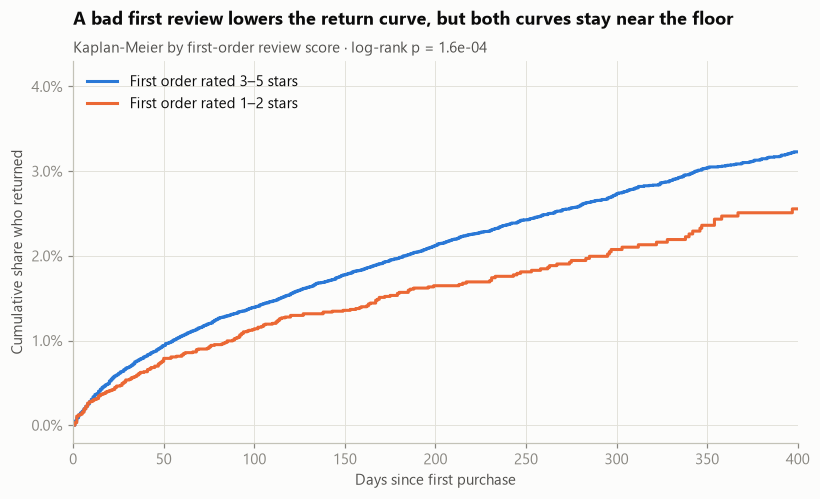

In [20]:
# Survival curves by first-order experience: same question, using everyone (with censoring) instead of a 180-day cut.
s = surv.dropna(subset=["review_score"]).copy()
s["neg"] = s.review_score <= 2
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for i, (flag, label) in enumerate([(False, "First order rated 3–5 stars"), (True, "First order rated 1–2 stars")]):
    g = s[s.neg == flag]
    k = KaplanMeierFitter().fit(g.duration, g.returned, label=label)
    ax.step(k.survival_function_.index, (1 - k.survival_function_.iloc[:, 0]) * 100, where="post", color=SERIES[i], label=label)
lr = logrank_test(s.loc[~s.neg, "duration"], s.loc[s.neg, "duration"], s.loc[~s.neg, "returned"], s.loc[s.neg, "returned"])
ax.set_xlim(0, 400)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.set(xlabel="Days since first purchase", ylabel="Cumulative share who returned")
ax.legend(loc="upper left")
titles(ax, "A bad first review lowers the return curve, but both curves stay near the floor",
       f"Kaplan-Meier by first-order review score · log-rank p = {lr.p_value:.1e}")
save(fig, "fig05_survival_by_experience")
plt.show()

**Reading the results: H1 holds.**
- A 1–2 star first order cuts the odds of returning by about 20 % (p ≈ 0.04), which is **−0.4 percentage points** off a 2 % base.
  The survival curves show the same gap with all follow-up included (log-rank p < 0.001).
- Lateness has **no separate effect** once the review is controlled for. It acts *through* the review. Its total effect
  (without the review term) is also small and statistically uncertain.
- If every 1–2 star first order had instead been rated 4–5 stars, the overall return rate would rise by only about
  0.05 points (13 % of customers × 0.4 pp). **The rest of the gap is structural.**

**Causal caution.** This is observational data. The controls remove obvious confounders (category, region, value,
timing), but unobserved factors, such as how a customer found the product, could still bias the estimate. The
direction is consistent across the logistic model and the survival curves, which is the most one can ask of this data.

**Implication:** the case for fixing delivery is **reviews**, not retention. Reviews feed seller ratings and the
conversion of *new* customers on the marketplaces, which is where the volume is.

## 5. Segmentation: does RFM work when almost nobody buys twice?

RFM (recency, frequency, monetary value) is the default customer segmentation. A standard SQL implementation scores
each dimension 1–5 with `NTILE(5)`:

In [21]:
%%sql rfm
WITH c AS (
    SELECT customer_unique_id,
           date_diff('day', max(purchased_at)::DATE, (SELECT window_end FROM params)) AS recency_days,
           count(*)                                                                  AS frequency,
           sum(payment_value)                                                        AS monetary
    FROM fct_orders, params
    WHERE purchase_seq IS NOT NULL AND purchased_at::DATE BETWEEN window_start AND window_end
    GROUP BY 1
),
scored AS (
    SELECT *,
           NTILE(5) OVER (ORDER BY recency_days DESC) AS r_score,
           NTILE(5) OVER (ORDER BY frequency)         AS f_score,
           NTILE(5) OVER (ORDER BY monetary)          AS m_score
    FROM c
)
SELECT f_score,
       count(*)                     AS customers,
       min(frequency)               AS min_orders,
       max(frequency)               AS max_orders,
       round(avg(frequency), 3)     AS avg_orders
FROM scored
GROUP BY 1 ORDER BY 1

,f_score,customers,min_orders,max_orders,avg_orders
0,1,18942,1,1,1.000
1,2,18942,1,1,1.000
2,3,18941,1,1,1.000
3,4,18941,1,1,1.000
4,5,18941,1,16,1.169


**RFM breaks here, silently.** About 97 % of customers have exactly one order, so `NTILE` has to split *identical*
customers into F-scores 1 to 5 arbitrarily, by whatever row order the database happens to use. Scores F1–F4 contain the
same one-order customers, so a "loyal F4" campaign would target random people. The query runs without error and
produces plausible-looking scores. That is exactly why it's dangerous.

A segmentation for this business has to be built from what *is* observed: **the first order.** Two dimensions matter
for repeat potential: what was bought, and how much was spent.

In [22]:
# Category "repeatability" from first orders, then 3 x 3 segments by category tier and order value.
cat_rate = c.groupby("category").returned_180.agg(["mean", "size"])
cat_rate = cat_rate[cat_rate["size"] >= 300]
c["cat_rate"] = c.category.map(cat_rate["mean"]).fillna(c.returned_180.mean())
c["cat_tier"] = pd.qcut(c.cat_rate.rank(method="first"), 3, labels=["low-repeat categories", "mid", "high-repeat categories"])
q1, q2 = c.items_value.quantile([1/3, 2/3]).round(0)
c["value_tier"] = pd.qcut(c.items_value, 3, labels=[f"< R${q1:.0f}", f"R${q1:.0f}–{q2:.0f}", f"> R${q2:.0f}"])
seg = c.groupby(["cat_tier", "value_tier"]).returned_180.agg(customers="size", returned="sum").reset_index()
seg["rate"] = seg.returned / seg.customers
seg["lo"], seg["hi"] = wilson(seg.returned, seg.customers)
print("Value-tier cut points (R$):", c.items_value.quantile([1/3, 2/3]).round(0).tolist())
seg.pivot(index="cat_tier", columns="value_tier", values="rate").style.format("{:.2%}")

Value-tier cut points (R$): [57.0, 120.0]


value_tier,< R$57,R$57–120,> R$120
cat_tier,,,
low-repeat categories,1.47%,1.54%,1.45%
mid,1.98%,1.73%,1.91%
high-repeat categories,2.61%,2.49%,2.88%


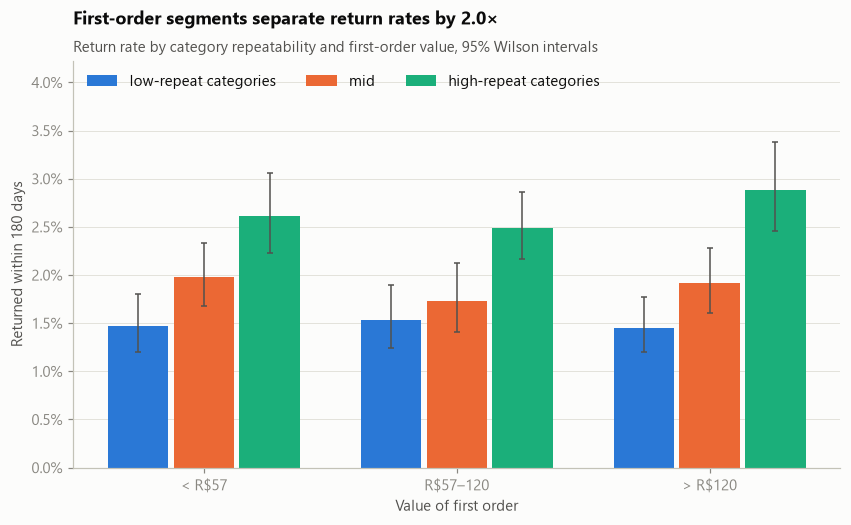

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(3)
w = 0.26
for i, tier in enumerate(seg.cat_tier.cat.categories):
    d = seg[seg.cat_tier == tier]
    ax.bar(x + (i - 1) * w, d.rate, w * 0.92, color=SERIES[i], label=tier)
    ax.errorbar(x + (i - 1) * w, d.rate, yerr=[d.rate - d.lo, d.hi - d.rate], fmt="none", ecolor=INK_2, elinewidth=1, capsize=2)
ax.set_xticks(x, seg.value_tier.cat.categories)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.grid(axis="x", visible=False)
ax.set(xlabel="Value of first order", ylabel="Returned within 180 days")
ax.set_ylim(0, seg.hi.max() * 1.25)
ax.legend(loc="upper left", ncol=3)
best, worst = seg.rate.max(), seg.rate.min()
titles(ax, f"First-order segments separate return rates by {best / worst:.1f}×",
       "Return rate by category repeatability and first-order value, 95% Wilson intervals")
save(fig, "fig06_segments")
plt.show()

These segments are honest: every customer is placed on facts about the order they actually made. **What was bought**
separates return rates by about 2×, while **how much was spent** barely matters within a category tier. They are still *descriptive*. Section 6 asks whether first-order
information can **predict** individual returns well enough to target.

*Note:* category rates here are computed on the same customers they describe, which flatters the spread slightly.
§6 avoids that leak by learning category rates on a training period only.

## 6. Can we predict who will return?

**Setup**
- **Time-based split:** train on first orders from Jan–Aug 2017 and test on Sep 2017 – Mar 2018. That is how the model
  would be used (learn from the past, score new customers). A random split would leak seasonality.
- **Features (first order only):** value, freight share, items, multi-seller, instalments, payment type, review score,
  late flag, delay, delivery time, distance, state, purchase month-of-year, and category repeat rate (target-encoded
  **on the training period only**, smoothed toward the mean).
- **Models:** regularised logistic regression as the baseline, and gradient boosting.

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance

d = c.copy()
d["moy"] = d.first_purchased_at.dt.month
d["log_km"] = np.log1p(d.distance_km.fillna(d.distance_km.median()))
train = d[d.first_purchased_at < "2017-09-01"].copy()
test = d[d.first_purchased_at >= "2017-09-01"].copy()

# Smoothed target encoding of category, fitted on train only (k = 200 pseudo-customers at the global mean).
g, k = train.returned_180.mean(), 200
enc = train.groupby("category").returned_180.agg(["sum", "size"])
enc = (enc["sum"] + k * g) / (enc["size"] + k)
for df_ in (train, test):
    df_["cat_te"] = df_.category.map(enc).fillna(g)

num = ["log_value", "freight_ratio", "n_items", "multi_seller", "installments", "review_score", "late",
       "delay_days", "delivery_days", "log_km", "cat_te", "moy"]
cat = ["payment_type", "state"]
X_tr, X_te, y_tr, y_te = train[num + cat], test[num + cat], train.returned_180, test.returned_180

prep = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
models = {
    "Logistic regression": make_pipeline(prep, LogisticRegression(C=0.5, max_iter=2000, class_weight="balanced")),
    "Gradient boosting": make_pipeline(ColumnTransformer([("num", "passthrough", num),
                                                          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)]),
                                       HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300,
                                                                      l2_regularization=1.0, random_state=0)),
}

def top_decile_lift(y, p):
    cut = np.quantile(p, 0.9)
    return y[p >= cut].mean() / y.mean()

rows, preds = [], {}
for name, mdl in models.items():
    mdl.fit(X_tr, y_tr)
    p = mdl.predict_proba(X_te)[:, 1]
    preds[name] = p
    rows.append({"model": name, "ROC AUC": roc_auc_score(y_te, p), "PR AUC": average_precision_score(y_te, p),
                 "PR AUC of random guess": y_te.mean(), "top-decile lift": top_decile_lift(y_te.to_numpy(), p)})
print(f"train {len(train):,} customers ({y_tr.mean():.2%} return) · test {len(test):,} customers ({y_te.mean():.2%} return)")
pd.DataFrame(rows).set_index("model")

train 21,229 customers (2.16% return) · test 34,513 customers (1.91% return)


,ROC AUC,PR AUC,PR AUC of random guess,top-decile lift
model,,,,
Logistic regression,0.547,0.021,0.019,1.064
Gradient boosting,0.543,0.022,0.019,1.303


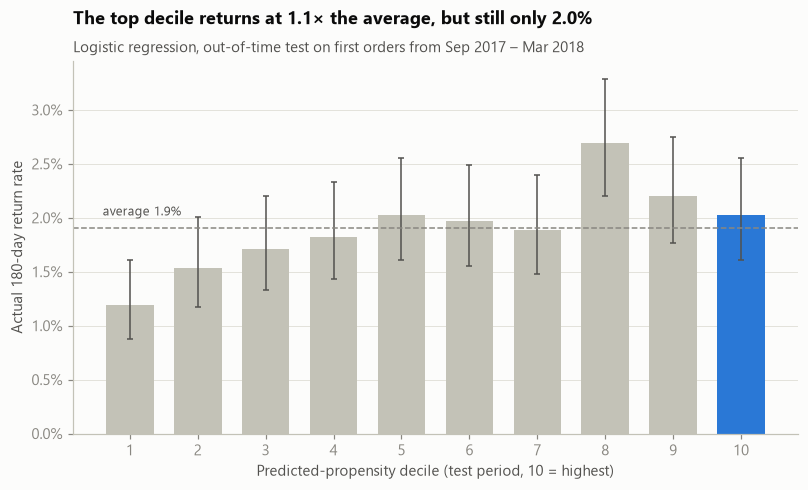

,AUC drop when shuffled
cat_te,0.027
state,0.009
delay_days,0.005
moy,0.005
installments,0.005
n_items,0.004
review_score,0.004
payment_type,0.002


In [25]:
best_name = max(preds, key=lambda n: roc_auc_score(y_te, preds[n]))
p = preds[best_name]
dec = pd.DataFrame({"y": y_te.to_numpy(), "p": p})
dec["decile"] = pd.qcut(dec.p.rank(method="first"), 10, labels=False) + 1
dd = dec.groupby("decile").y.agg(["mean", "sum", "size"])
dd["lo"], dd["hi"] = wilson(dd["sum"], dd["size"])

fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.bar(dd.index, dd["mean"], color=[HIGHLIGHT if i == 10 else CONTEXT for i in dd.index], width=0.7)
ax.errorbar(dd.index, dd["mean"], yerr=[dd["mean"] - dd.lo, dd.hi - dd["mean"]], fmt="none", ecolor=INK_2, elinewidth=1, capsize=2)
ax.axhline(y_te.mean(), color=MUTED, linestyle="--", linewidth=1)
ax.text(0.6, y_te.mean() * 1.06, f"average {y_te.mean():.1%}", color=INK_2, fontsize=8.5)
ax.set_xticks(range(1, 11))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.grid(axis="x", visible=False)
ax.set(xlabel="Predicted-propensity decile (test period, 10 = highest)", ylabel="Actual 180-day return rate")
lift = dd["mean"].iloc[-1] / y_te.mean()
titles(ax, f"The top decile returns at {lift:.1f}× the average, but still only {dd['mean'].iloc[-1]:.1%}",
       f"{best_name}, out-of-time test on first orders from Sep 2017 – Mar 2018")
save(fig, "fig07_model_lift")
plt.show()

imp = permutation_importance(models[best_name], X_te, y_te, scoring="roc_auc", n_repeats=10, random_state=0)
pd.Series(imp.importances_mean, index=num + cat).sort_values(ascending=False).head(8).rename("AUC drop when shuffled").to_frame()

**Reading the model honestly**
- Both models score an **AUC of about 0.55**, barely better than a coin flip (0.50), and top-decile lift is only 1.1–1.3×.
  First-order data **cannot** tell future returners from one-time buyers.
- That is a finding, not a failure. It is exactly what H1 predicts: if returning were driven by the observable first-order
  experience, a model would pick it up. A model claiming AUC 0.9 here would be a red flag for leakage.
- The most informative feature is **category** (the target encoding), matching §5. Review and delay add almost nothing.
- **Business implication:** don't fund a propensity-based retention programme on this data. Any retention budget should be
  a cheap, untargeted touch (for example, a post-purchase email), not personalised vouchers.

## 7. Who causes late deliveries: sellers or routes?

If reviews are the lever, the next question is operational: where does lateness come from?

### 7.1 Where the time goes

In [26]:
%%sql legs
SELECT CASE WHEN is_late THEN 'late orders' ELSE 'on-time orders' END AS orders,
       count(*)                                                AS n,
       round(median(seller_days), 1)                           AS median_days_seller_to_carrier,
       round(median(carrier_days), 1)                          AS median_days_carrier_to_customer,
       round(avg(seller_missed_handover::INT), 3)              AS share_seller_missed_handover_deadline,
       round(median(distance_km), 0)                           AS median_km
FROM fct_orders, params
WHERE order_status = 'delivered' AND delivered_at IS NOT NULL AND carrier_at IS NOT NULL
  AND purchased_at::DATE BETWEEN window_start AND window_end
GROUP BY 1

,orders,n,median_days_seller_to_carrier,median_days_carrier_to_customer,share_seller_missed_handover_deadline,median_km
0,late orders,6530,3.5,26.2,0.277,529.0
1,on-time orders,89672,2.1,7.0,0.075,426.0


Late orders spend about 1.4 extra days with the seller (3.5 vs 2.1) but about **19 extra days with the carrier**
(26 vs 7). Most lateness is a **logistics** problem. Seller handover misses are a real but smaller factor: 28 % of late
orders started with the seller missing the deadline, against 7.5 % of on-time orders.

### 7.2 Are a few sellers responsible? (empirical-Bayes shrinkage)

Raw seller late rates are noisy: a seller with 3 orders and 1 late delivery shows 33 %. **Empirical-Bayes shrinkage**
pulls each seller's rate toward the platform average in proportion to how little data they have, using a
beta-binomial prior fitted to all sellers.

In [27]:
%%sql sellers
SELECT seller_id, seller_state,
       count(*)                    AS orders,
       sum(is_late::INT)           AS late,
       sum(seller_missed_handover::INT) AS missed_handover
FROM fct_orders, params
WHERE order_status = 'delivered' AND delivered_at IS NOT NULL
  AND purchased_at::DATE BETWEEN window_start AND window_end
GROUP BY 1, 2

,seller_id,seller_state,orders,late,missed_handover
0,12b9676b00f60f3b700e83af21824c0e,RS,133,1.0,1.0
1,e9bc59e7b60fc3063eb2290deda4cced,PR,203,16.0,54.0
2,5dceca129747e92ff8ef7a997dc4f8ca,SP,320,18.0,13.0
3,7ddcbb64b5bc1ef36ca8c151f6ec77df,SP,324,27.0,3.0
4,cbd996ad3c1b7dc71fd0e5f5df9087e2,SP,160,13.0,5.0
...,...,...,...,...,...
2930,cd2169d9f31ff6fbb9ca3373b0c9e354,RJ,1,0.0,0.0
2931,fc4751cfe3b279c419615b9b00c1abb4,PR,1,0.0,0.0
2932,8e670472e453ba34a379331513d6aab1,MG,1,1.0,1.0
2933,5e25c632f9db6cfb8bc100421c2737b6,SC,1,0.0,0.0


Prior: Beta(2.97, 41.45) · mean 6.68% · equivalent to 44 pseudo-orders
Sellers handling the worst 10% of order volume: 142 sellers, 23.1% of all late orders, late rate 15.7% vs platform 6.8%


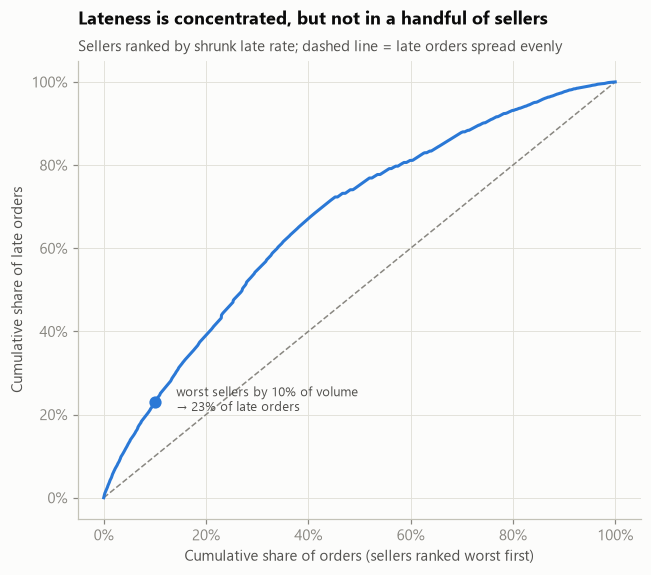

In [28]:
# Fit a Beta(a, b) prior by maximum likelihood on sellers' (late, orders), then shrink.
from scipy.special import betaln
def nll(params, k, n):
    a, b = np.exp(params)
    return -np.sum(betaln(k + a, n - k + b) - betaln(a, b))
opt = __import__("scipy.optimize", fromlist=["minimize"]).minimize(nll, [0, 2], args=(sellers.late.values, sellers.orders.values))
a, b = np.exp(opt.x)
sellers["raw_rate"] = sellers.late / sellers.orders
sellers["shrunk_rate"] = (sellers.late + a) / (sellers.orders + a + b)
print(f"Prior: Beta({a:.2f}, {b:.2f}) · mean {a / (a + b):.2%} · equivalent to {a + b:.0f} pseudo-orders")

# Concentration: rank sellers by shrunk late rate; what share of late orders do the worst sellers generate?
s_ = sellers.sort_values("shrunk_rate", ascending=False)
s_["cum_orders"] = s_.orders.cumsum() / s_.orders.sum()
s_["cum_late"] = s_.late.cumsum() / s_.late.sum()
worst10 = s_[s_.cum_orders <= 0.10]
excess = (worst10.late - worst10.orders * sellers.late.sum() / sellers.orders.sum()).sum()
print(f"Sellers handling the worst 10% of order volume: {len(worst10):,} sellers, "
      f"{worst10.late.sum() / sellers.late.sum():.1%} of all late orders, "
      f"late rate {worst10.late.sum() / worst10.orders.sum():.1%} vs platform {sellers.late.sum() / sellers.orders.sum():.1%}")

gini = 1 - 2 * np.trapezoid(s_.cum_late.values[::-1], s_.cum_orders.values[::-1]) if hasattr(np, "trapezoid") else np.nan
fig, ax = plt.subplots(figsize=(6.6, 5.4))
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
ax.plot(np.r_[0, s_.cum_orders], np.r_[0, s_.cum_late], color=HIGHLIGHT)
ax.plot(0.10, worst10.late.sum() / sellers.late.sum(), "o", color=HIGHLIGHT)
ax.annotate(f"worst sellers by 10% of volume\n→ {worst10.late.sum() / sellers.late.sum():.0%} of late orders",
            (0.10, worst10.late.sum() / sellers.late.sum()), xytext=(14, -6), textcoords="offset points", fontsize=8.5, color=INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set(xlabel="Cumulative share of orders (sellers ranked worst first)", ylabel="Cumulative share of late orders")
titles(ax, "Lateness is concentrated, but not in a handful of sellers",
       "Sellers ranked by shrunk late rate; dashed line = late orders spread evenly")
save(fig, "fig08_seller_concentration")
plt.show()

In [29]:
%%sql routes
SELECT customer_state,
       count(*)                          AS orders,
       round(avg(is_late::INT), 3)        AS late_rate,
       round(median(carrier_days), 1)     AS median_carrier_days,
       round(median(promised_days), 0)    AS median_promised_days
FROM fct_orders, params
WHERE order_status = 'delivered' AND delivered_at IS NOT NULL
  AND purchased_at::DATE BETWEEN window_start AND window_end
GROUP BY 1
HAVING count(*) >= 300
ORDER BY late_rate DESC

,customer_state,orders,late_rate,median_carrier_days,median_promised_days
0,AL,396,0.215,18.1,32.0
1,MA,713,0.175,15.7,31.0
2,SE,332,0.154,14.2,30.0
3,PI,475,0.139,13.5,30.0
4,CE,1273,0.138,14.8,32.0
5,BA,3253,0.122,13.8,30.0
6,RJ,12310,0.121,8.4,25.0
7,PA,942,0.113,17.3,37.0
8,ES,1992,0.107,10.0,26.0
9,PB,516,0.105,14.1,33.0


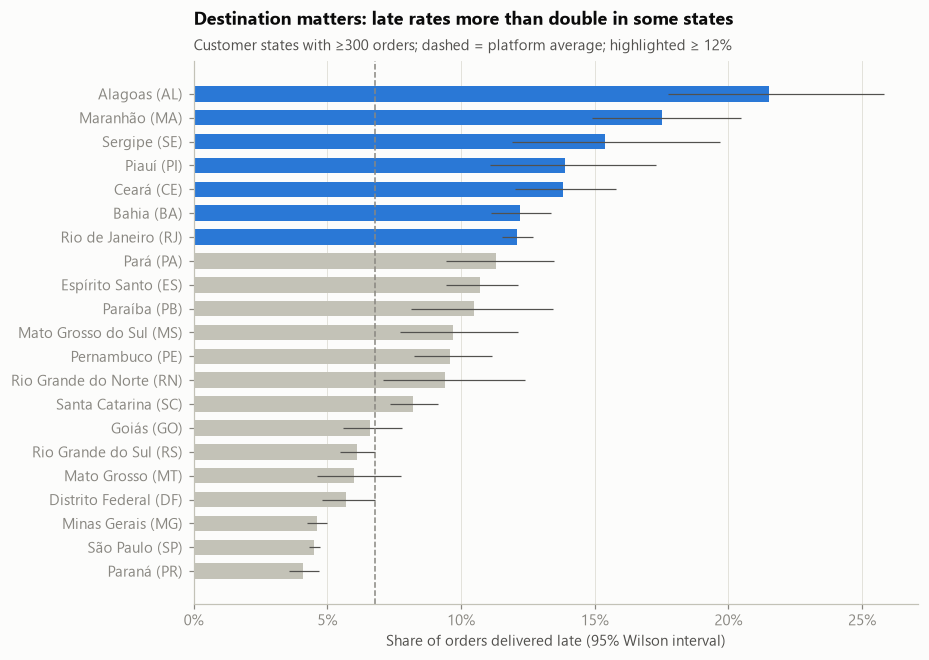

In [30]:
STATE_NAMES = {"AC": "Acre", "AL": "Alagoas", "AM": "Amazonas", "AP": "Amapá", "BA": "Bahia", "CE": "Ceará",
               "DF": "Distrito Federal", "ES": "Espírito Santo", "GO": "Goiás", "MA": "Maranhão", "MG": "Minas Gerais",
               "MS": "Mato Grosso do Sul", "MT": "Mato Grosso", "PA": "Pará", "PB": "Paraíba", "PE": "Pernambuco",
               "PI": "Piauí", "PR": "Paraná", "RJ": "Rio de Janeiro", "RN": "Rio Grande do Norte", "RO": "Rondônia",
               "RR": "Roraima", "RS": "Rio Grande do Sul", "SC": "Santa Catarina", "SE": "Sergipe", "SP": "São Paulo",
               "TO": "Tocantins"}
r = routes.sort_values("late_rate")
r["label"] = [f"{STATE_NAMES.get(s_, s_)} ({s_})" for s_ in r.customer_state]
lo_, hi_ = wilson(r.late_rate * r.orders, r.orders)
fig, ax = plt.subplots(figsize=(8.5, 6.4))
colors = [HIGHLIGHT if v >= 0.12 else CONTEXT for v in r.late_rate]
ax.barh(r.label, r.late_rate, color=colors, height=0.65)
ax.errorbar(r.late_rate, r.label, xerr=[r.late_rate - lo_, hi_ - r.late_rate], fmt="none", ecolor=INK_2, elinewidth=0.8)
ax.axvline(routes.late_rate.mul(routes.orders).sum() / routes.orders.sum(), color=MUTED, linestyle="--", linewidth=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Share of orders delivered late (95% Wilson interval)")
titles(ax, "Destination matters: late rates more than double in some states",
       "Customer states with ≥300 orders; dashed = platform average; highlighted ≥ 12%")
save(fig, "fig09_late_by_state")
plt.show()

Rates alone hide volume. A state with a moderate late rate but huge order volume can produce more late orders than a
small state with a terrible rate. **Excess late orders** (actual late orders minus what the state would have at the
best large-state rate) rank where fixing routes removes the most lateness:

In [31]:
benchmark = routes.loc[routes.orders >= 5000, "late_rate"].min()   # best large-state rate
ex = routes.assign(late_orders=lambda d: (d.late_rate * d.orders).round(),
                   excess_late=lambda d: ((d.late_rate - benchmark) * d.orders).clip(lower=0).round())
ex["share_of_all_excess"] = ex.excess_late / ex.excess_late.sum()
print(f"Benchmark late rate: {benchmark:.1%} · total late orders {ex.late_orders.sum():,.0f} · excess {ex.excess_late.sum():,.0f}")
ex.sort_values("excess_late", ascending=False).head(6)[["customer_state", "orders", "late_rate", "late_orders", "excess_late", "share_of_all_excess"]]

Benchmark late rate: 4.5% · total late orders 6,482 · excess 2,210


,customer_state,orders,late_rate,late_orders,excess_late,share_of_all_excess
6,RJ,12310,0.121,1490.0,936.0,0.424
5,BA,3253,0.122,397.0,250.0,0.113
13,SC,3537,0.082,290.0,131.0,0.059
8,ES,1992,0.107,213.0,124.0,0.056
4,CE,1273,0.138,176.0,118.0,0.053
1,MA,713,0.175,125.0,93.0,0.042


**What this says about where to act**
1. **Carrier and route performance is the main lever.** Late orders lose their time in transit, and late rates vary strongly
   by destination state even though promised dates already allow more time for distant states. **Rio de Janeiro alone**
   accounts for the largest block of excess late orders: a 12 % late rate on more than 12,000 orders.
2. **A seller programme is a secondary lever.** The worst sellers by volume generate more than their share of late orders,
   but not overwhelmingly so. Enforcing handover deadlines helps, but it won't fix the bulk.

## 8. What is fixing it worth?

A counterfactual simulation using the §3 review model and the §4 repurchase model:
- **Scenario A:** half of today's late orders arrive on time instead (for example, through carrier changes on the worst routes).
- **Scenario B:** every late order arrives on time (an upper bound).

Uncertainty comes from the models themselves: 2,000 coefficient draws from each model's estimated sampling
distribution give the intervals.

In [32]:
def simulate(res, data, share_fixed, outcome_cols, n_draws=2000, seed=1):
    rng = np.random.default_rng(seed)
    base = data.copy()
    late_idx = base.index[base.late == 1]
    fixed = rng.choice(late_idx, int(len(late_idx) * share_fixed), replace=False)
    cf = base.copy()
    cf.loc[fixed, "late"] = 0
    if "bucket" in cf:
        cf.loc[fixed, "bucket"] = "0–6 early"
    # Design matrices from the fitted formula, then propagate coefficient uncertainty.
    from patsy import dmatrix
    di = res.model.data.model_spec      # patsy DesignInfo from the fitted formula
    Xb, Xc = np.asarray(dmatrix(di, base, return_type="dataframe")), np.asarray(dmatrix(di, cf, return_type="dataframe"))
    draws = rng.multivariate_normal(res.params.values, res.cov_params().values, size=n_draws)
    pb = 1 / (1 + np.exp(-(Xb @ draws.T)))
    pc = 1 / (1 + np.exp(-(Xc @ draws.T)))
    delta = (pc - pb).sum(axis=0)          # change in expected count, per draw
    return np.percentile(delta, [50, 2.5, 97.5])

rows = []
for label, share in [("A: half of late orders on time", 0.5), ("B: all late orders on time", 1.0)]:
    neg = simulate(logit_neg, m, share, "negative")
    ret_ = simulate(logit_ret_total, c, share, "returned_180")   # total effect: includes the path through reviews
    rows.append({"scenario": label,
                 "1–2 star reviews avoided per 10k orders": -neg[0] / len(m) * 1e4,
                 "95% CI (reviews)": f"{-neg[2] / len(m) * 1e4:.0f} – {-neg[1] / len(m) * 1e4:.0f}",
                 "extra returning customers per 10k": ret_[0] / len(c) * 1e4,
                 "95% CI (customers)": f"{ret_[1] / len(c) * 1e4:.1f} – {ret_[2] / len(c) * 1e4:.1f}"})
impact = pd.DataFrame(rows).set_index("scenario")
impact

,1–2 star reviews avoided per 10k orders,95% CI (reviews),extra returning customers per 10k,95% CI (customers)
scenario,,,,
A: half of late orders on time,166.827,163 – 171,1.083,-0.6 – 2.5
B: all late orders on time,333.455,325 – 342,2.170,-1.1 – 4.8


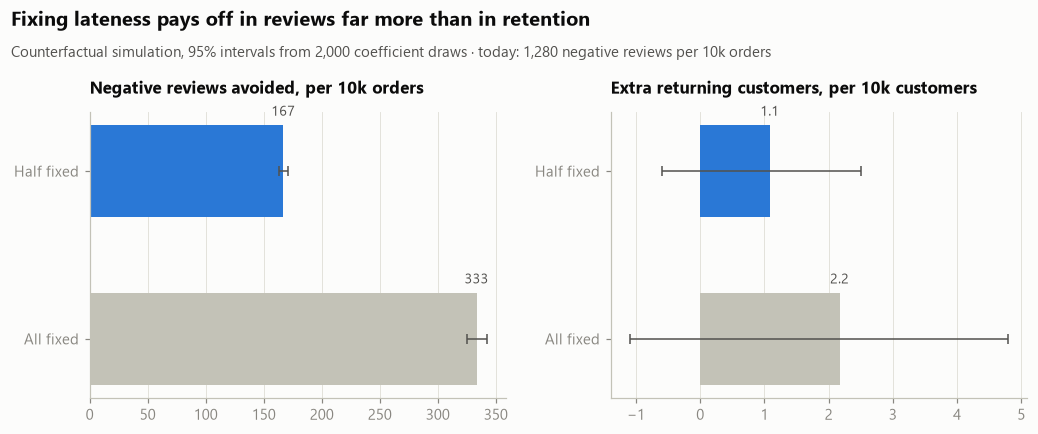

In [33]:
neg_now = m.negative.mean() * 1e4
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, ci, title, unit in [
    (axes[0], "1–2 star reviews avoided per 10k orders", "95% CI (reviews)", "Negative reviews avoided", "per 10k orders"),
    (axes[1], "extra returning customers per 10k", "95% CI (customers)", "Extra returning customers", "per 10k customers"),
]:
    vals = impact[col]
    lo_hi = np.array([[float(x) for x in s.split(" – ")] for s in impact[ci]])
    y = np.arange(len(vals))[::-1]
    ax.barh(y, vals, color=[HIGHLIGHT, CONTEXT], height=0.55)
    ax.errorbar(vals, y, xerr=[vals - lo_hi[:, 0], lo_hi[:, 1] - vals], fmt="none", ecolor=INK_2, elinewidth=1, capsize=3)
    for yy, v in zip(y, vals):
        ax.text(v, yy + 0.33, f"{v:,.0f}" if v >= 10 else f"{v:.1f}", ha="center", fontsize=9, color=INK_2)
    ax.set_yticks(y, ["Half fixed", "All fixed"])
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{title}, {unit}", loc="left", fontsize=11)
fig.subplots_adjust(top=0.76, wspace=0.25)
fig.suptitle("Fixing lateness pays off in reviews far more than in retention", x=0.06, ha="left", fontsize=13, weight="bold", y=0.99)
fig.text(0.06, 0.885, f"Counterfactual simulation, 95% intervals from 2,000 coefficient draws · today: {neg_now:,.0f} negative reviews per 10k orders",
         color=INK_2, fontsize=9.5)
save(fig, "fig10_impact")
plt.show()

**Reading the simulation**
- Halving late deliveries avoids about **167 negative reviews per 10,000 orders**. Today there are about 1,280 per 10,000,
  so that is a **~13 % cut** in negative reviews. Fixing every late order would roughly double that.
- The same change adds about **1 returning customer per 10,000**, and the interval includes zero. This uses the *total*
  effect of lateness (model without the review term), so it already includes the path through reviews.
- The intervals reflect uncertainty in the model coefficients only. They do not cover model misspecification or the
  observational design, so they are a lower bound on the real uncertainty.

## 9. Recommendation

| Priority | Action | Why | Expected effect |
|---|---|---|---|
| **1** | **Fix the Rio de Janeiro delivery route** (carrier performance review, alternative carrier pilot) | Largest single source of excess lateness: 42 % of the total | Bringing RJ to São Paulo's 4.5 % late rate removes **~940 late orders**, 14 % of all late orders |
| **2** | **Extend to the next worst routes** (Bahia, then Ceará and Maranhão) | Same carrier pattern, smaller volume | RJ + Bahia cover 54 % of excess late orders; adding Ceará and Maranhão brings it to 63 % |
| **3** | **Enforce seller handover deadlines** for the worst sellers | 142 sellers handle 10 % of volume but cause 23 % of late orders; missed handovers are nearly 4× more common on late orders | Secondary lever; cheaper to run than a carrier change |
| **4** | **Run an A/B test on tighter delivery promises** | Promises average 24 days against a median actual of 10, and customers reward early delivery only slightly | Possible conversion gain; must be tested, because a tighter promise creates more "late" orders |
| **Don't** | **Fund a targeted retention programme** | Retention is structural, and first-order data can't identify returners (AUC 0.55) | Keep retention spend to cheap, untargeted touches |

**Success metric:** share of orders delivered late, tracked by destination state, with the share of 1–2 star reviews as
the outcome. Not repeat rate.

## 10. Limitations

| Limitation | Effect | How I'd address it |
|---|---|---|
| Observational data, no experiments | Effects are associations with controls, not proven causes | A/B test tighter delivery promises; pilot a carrier switch on 2–3 worst routes |
| One marketplace integrator, Brazil, 2017–2018 | May not transfer to other markets or periods | Re-run on recent data; the SQL model is reusable |
| No marketing, traffic or marketplace-ranking data | Can't link reviews to sales directly | Join review scores to listing conversion data, if available |
| Reviews exist for 99 % of orders but may be prompted differently by channel | Possible measurement bias in scores | Check score distributions by sales channel |
| 180-day return window | Long-cycle categories (furniture, electronics) are under-counted | The survival analysis in §2 and §4 uses all follow-up, which partly covers this |